# Give Me Some Credit 💸
### Exercise 4 — Credit Delinquency Prediction, Imbalanced Classification, and Model Optimization

**Source folder:** `session_3/5.give_me_some_credit/`  
**Prediction target:** `SeriousDlqin` (`0` = not delinquent; `1` = delinquent)  
**Objective:** Complete a reproducible preparation-and-modeling workflow and investigate whether a Random Forest can actually detect delinquency rather than merely achieve high overall accuracy.

### Assignment requirements and notebook roadmap

| Requirement | Implemented in | Evidence to inspect |
|:--|:--|:--|
| **A.** Export prepared training and testing data without a DataFrame index | Section 3 | `train.csv` and `test.csv` created with `index=False` |
| **B.** Report precision, recall, F1-score, and support for delinquency; show a labeled confusion matrix; explain the accuracy paradox | Sections 4–5 and 9 | Class-1 classification metrics, true/false positives and negatives, baseline and final confusion matrices |
| **C.** Investigate balancing, outlier removal, alternative classifiers, and hyperparameter tuning | Sections 6–8 | SMOTENC, fold-wise IQR filtering, model comparisons, `RandomizedSearchCV`, and selected hyperparameters |

> **Key evaluation principle:** The positive class is `SeriousDlqin = 1`. With a rare positive class, overall accuracy is insufficient: missing delinquent cases (false negatives) must be measured explicitly.

> **Dataset terminology:** In this notebook, `test.csv` is the **labeled 20% holdout** created from the supplied dataset, not an unlabeled Kaggle competition submission file. It is kept separate from model selection until final evaluation.

---

## 0. Environment and Reproducibility

The code below imports data preparation, preprocessing, tree-based and linear models, imbalanced-learning utilities, cross-validation, model-selection tools, and classification metrics. `RANDOM_STATE = 42` is reused where explicitly supported by the original implementation.

**Required input:** A CSV named `GiveMeSomeCredit.csv` in the notebook's working directory. The provided upload may have a date suffix; **rename or copy the input file** to the expected filename before running this unchanged code. The notebook also requires `scikit-learn`, `imbalanced-learn`, `pandas`, `numpy`, `matplotlib`, and Jupyter/IPython.


In [25]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC

RANDOM_STATE = 42

## 1. Load and Inspect the Source Dataset

The source file is loaded without modifying its contents. Shape, column names, sample records, data types, and descriptive statistics establish the dataset's structure before any preprocessing decisions are made.

**Recorded dataset:** **149,724 rows and 14 columns**, including the binary target `SeriousDlqin` and a suspected target-proxy feature that is investigated later.


In [26]:
df = pd.read_csv("GiveMeSomeCredit.csv")

print('Shape:', df.shape)
print('\nColumns:')
print(df.columns.tolist())
print('\nHead:')
display(df.head())
print('\nInfo:')
df.info()
print('\nDescribe:')
display(df.describe(include='all').T)
print('\nData types:')
display(df.dtypes.to_frame('dtype'))

Shape: (149724, 14)

Columns:
['SeriousDlqin', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'SEX', 'EDUCATION', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'NumberOfDefault']

Head:


,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
0,1,0.878881,40,F,3,0,0.605616,12000.0,19,2,3,11,0.0,1
1,0,1.000000,34,F,1,3,2121.000000,0.0,9,0,2,9,2.0,0
2,0,0.470085,59,F,1,5,1.280078,15916.0,34,6,14,8,0.0,0
3,1,0.908082,26,M,3,3,1.444855,6500.0,22,1,4,8,0.0,2
4,1,1.000000,36,M,3,4,0.913676,2200.0,10,1,1,7,1.0,1



Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149724 entries, 0 to 149723
Data columns (total 14 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin                          149724 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  149724 non-null  float64
 2   age                                   149724 non-null  int64  
 3   SEX                                   149724 non-null  object 
 4   EDUCATION                             149724 non-null  int64  
 5   NumberOfTime30-59DaysPastDueNotWorse  149724 non-null  int64  
 6   DebtRatio                             149724 non-null  float64
 7   MonthlyIncome                         120117 non-null  float64
 8   NumberOfOpenCreditLinesAndLoans       149724 non-null  int64  
 9   NumberOfTimes90DaysLate               149724 non-null  int64  
 10  NumberRealEstateLoansOrLines          149724 non-null  int64 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
SeriousDlqin,149724.0,NaN,NaN,NaN,0.065981,0.24825,0.0,0.0,0.0,0.0,1.0
RevolvingUtilizationOfUnsecuredLines,149724.0,NaN,NaN,NaN,5.719113,212.891876,0.0,0.029774,0.153492,0.555611,29110.0
age,149724.0,NaN,NaN,NaN,52.327489,14.75517,0.0,41.0,52.0,63.0,109.0
SEX,149724,2,F,90034,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EDUCATION,149724.0,NaN,NaN,NaN,2.199734,0.872731,1.0,1.0,2.0,3.0,4.0
NumberOfTime30-59DaysPastDueNotWorse,149724.0,NaN,NaN,NaN,0.245792,0.697789,0.0,0.0,0.0,0.0,13.0
DebtRatio,149724.0,NaN,NaN,NaN,347.212896,1448.290078,0.0,0.175989,0.367117,0.869897,220516.0
MonthlyIncome,120117.0,NaN,NaN,NaN,6650.02719,11493.934709,0.0,3400.0,5400.0,8250.0,1794060.0
NumberOfOpenCreditLinesAndLoans,149724.0,NaN,NaN,NaN,8.467547,5.136571,0.0,5.0,8.0,11.0,57.0
NumberOfTimes90DaysLate,149724.0,NaN,NaN,NaN,0.090446,0.485513,0.0,0.0,0.0,0.0,17.0



Data types:


,dtype
SeriousDlqin,int64
RevolvingUtilizationOfUnsecuredLines,float64
age,int64
SEX,object
EDUCATION,int64
NumberOfTime30-59DaysPastDueNotWorse,int64
DebtRatio,float64
MonthlyIncome,float64
NumberOfOpenCreditLinesAndLoans,int64
NumberOfTimes90DaysLate,int64


### 1.1 Data Quality, Class Imbalance, and Exploratory Checks

This step examines missingness, exact duplicates, feature cardinalities, the target distribution, and categorical frequencies. The chart contrasts the majority class (`0`) with delinquency (`1`).

The uploaded data contain **142 duplicate rows**. The observed minority class accounts for approximately **6.6%** of records, confirming a substantially imbalanced classification problem.

**Why this matters:** A classifier predicting only class `0` could already achieve approximately **93.4% accuracy**, while identifying **zero** true delinquent cases. Therefore, positive-class recall and F1 must accompany accuracy.


Missing values:


,missing_count
SeriousDlqin,0
RevolvingUtilizationOfUnsecuredLines,0
age,0
SEX,0
EDUCATION,0
NumberOfTime30-59DaysPastDueNotWorse,0
DebtRatio,0
MonthlyIncome,29607
NumberOfOpenCreditLinesAndLoans,0
NumberOfTimes90DaysLate,0


Duplicate rows: 142

Unique values per column:


,n_unique
SeriousDlqin,2
RevolvingUtilizationOfUnsecuredLines,125722
age,86
SEX,2
EDUCATION,4
NumberOfTime30-59DaysPastDueNotWorse,14
DebtRatio,114167
MonthlyIncome,13591
NumberOfOpenCreditLinesAndLoans,57
NumberOfTimes90DaysLate,17


,count,percent
SeriousDlqin,,
0,139845,93.402
1,9879,6.598


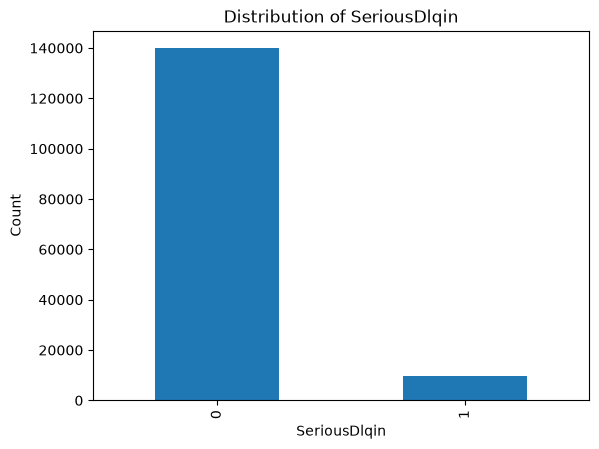

SEX values:


,count
SEX,
F,90034
M,59690


EDUCATION values:


,count
EDUCATION,
1,37562
2,52186
3,52485
4,7491


Class 1 percentage: 6.598%
Conclusion: the target is clearly imbalanced.


In [27]:
TARGET = 'SeriousDlqin'

print('Missing values:')
display(df.isna().sum().to_frame('missing_count'))

print('Duplicate rows:', df.duplicated().sum())

print('\nUnique values per column:')
display(df.nunique(dropna=False).to_frame('n_unique'))

class_counts = df[TARGET].value_counts().sort_index()
class_pct = (df[TARGET].value_counts(normalize=True).sort_index() * 100).round(3)

target_summary = pd.DataFrame({'count': class_counts, 'percent': class_pct})
display(target_summary)

ax = class_counts.plot(kind='bar', title='Distribution of SeriousDlqin')
ax.set_xlabel('SeriousDlqin')
ax.set_ylabel('Count')
plt.show()

print('SEX values:')
display(df['SEX'].value_counts(dropna=False).to_frame('count'))
print('EDUCATION values:')
display(df['EDUCATION'].value_counts(dropna=False).sort_index().to_frame('count'))

minority_pct = class_pct.get(1, 0)
print(f'Class 1 percentage: {minority_pct:.3f}%')
if minority_pct < 30:
    print('Conclusion: the target is clearly imbalanced.')
else:
    print('Conclusion: the target is not strongly imbalanced.')

### 1.2 Identify Categorical Features and a Potential Target-Information Leak

`SEX` and `EDUCATION` are handled as categorical variables. The field `NumberOfDefault` is flagged for a leakage check because it may encode information that is equivalent or extremely close to the target.

A feature that reveals the outcome at prediction time would produce misleadingly optimistic model scores and should not be treated as a legitimate predictor.


In [28]:
CATEGORICAL_COLS = ['SEX', 'EDUCATION']
LEAKAGE_CANDIDATE = 'NumberOfDefault'

print('Categorical:', CATEGORICAL_COLS)
print('Target:', TARGET)
print('Leakage candidate:', LEAKAGE_CANDIDATE)

Categorical: ['SEX', 'EDUCATION']
Target: SeriousDlqin
Leakage candidate: NumberOfDefault


### 1.3 Verify Target Leakage Before Modeling

The normalized cross-tabulation and the explicit Boolean equality test assess whether `NumberOfDefault` deterministically separates the target. In the saved output, **`Target leakage: True`**: zero values correspond to class `0`, while positive values correspond to class `1`.

**Decision:** Exclude `NumberOfDefault` from model inputs and the prepared exports. This is a necessary modeling safeguard and is distinct from optional feature selection.


In [29]:
display(pd.crosstab(
    df[LEAKAGE_CANDIDATE],
    df[TARGET],
    normalize='index'
).round(4))

print(
    'Target leakage:',
    ((df[LEAKAGE_CANDIDATE] == 0) == (df[TARGET] == 0)).all()
)

SeriousDlqin,0,1
NumberOfDefault,,
0,1.0,0.0
1,0.0,1.0
2,0.0,1.0
3,0.0,1.0


Target leakage: True


## 2. Prepare the Modeling Population
### 2.1 Remove Exact Duplicate Records

Duplicate rows are removed before partitioning to prevent the same complete record from appearing in both training and test partitions.

| Recorded quantity | Rows |
|:--|--:|
| Before duplicate removal | 149,724 |
| After duplicate removal | 149,582 |
| Exact duplicates removed | 142 |

No test-set label or outcome information is used to fit a model in this step.


In [30]:
rows_before = len(df)
df_clean = df.drop_duplicates().copy()
rows_after = len(df_clean)

print('Rows before duplicate removal:', rows_before)
print('Rows after duplicate removal :', rows_after)
print('Removed duplicates           :', rows_before - rows_after)

Rows before duplicate removal: 149724
Rows after duplicate removal : 149582
Removed duplicates           : 142


### 2.2 Stratified Training/Test Split

The target column and the verified leakage column are excluded from predictors. The remaining data are separated with an **80/20 stratified split**, using `random_state=42`.

| Partition | Rows | Predictor columns |
|:--|--:|--:|
| Development / training | 119,665 | 12 |
| Reserved holdout / test | 29,917 | 12 |

Stratification preserves approximately the same class proportions in both subsets (the training subset contains **6.604% class 1**). The holdout remains outside model-selection cross-validation.


In [31]:
X = df_clean.drop(columns=[TARGET, LEAKAGE_CANDIDATE])
y = df_clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

print('Train shape:', X_train.shape)
print('Test shape :', X_test.shape)
print('\nTrain target distribution:')
display((y_train.value_counts(normalize=True).sort_index() * 100).round(3).to_frame('percent'))
print('Test target distribution:')
display((y_test.value_counts(normalize=True).sort_index() * 100).round(3).to_frame('percent'))

Train shape: (119665, 12)
Test shape : (29917, 12)

Train target distribution:


,percent
SeriousDlqin,
0,93.396
1,6.604


Test target distribution:


,percent
SeriousDlqin,
0,93.395
1,6.605


### 2.3 Define Leakage-Aware Preprocessing Pipelines

The notebook constructs two preprocessing alternatives:

- **One-hot encoding:** median imputation for numerical inputs; most-frequent imputation plus one-hot encoding for `SEX` and `EDUCATION`.
- **Ordinal encoding:** the same numerical treatment; most-frequent imputation and integer encoding for categorical inputs, suitable for the downstream SMOTENC experiments.

Embedding these transformations within estimators allows each cross-validation fold to learn imputation statistics and encodings from **its own training partition**, rather than from its validation partition. Unknown categorical values are handled according to the respective encoder's configuration.


In [32]:
NUMERICAL_COLS = [c for c in X.columns if c not in CATEGORICAL_COLS]

numeric_preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
])

categorical_onehot = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor_ohe = ColumnTransformer([
    ('num', numeric_preprocessor, NUMERICAL_COLS),
    ('cat', categorical_onehot, CATEGORICAL_COLS),
])

categorical_ordinal = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
])

preprocessor_ordinal = ColumnTransformer([
    ('num', numeric_preprocessor, NUMERICAL_COLS),
    ('cat', categorical_ordinal, CATEGORICAL_COLS),
])

print('Numerical columns:')
print(NUMERICAL_COLS)
print('\nCategorical columns:')
print(CATEGORICAL_COLS)

Numerical columns:
['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']

Categorical columns:
['SEX', 'EDUCATION']


## 3. Export Prepared Data — Part A

The code constructs explicit prepared training and holdout tables. It estimates numerical medians and categorical modes **from the training subset only**, applies those same values to both partitions, and restores the `SeriousDlqin` label for each exported table.

The following two exports directly satisfy **Part A**:

```python
train_prepared.to_csv('train.csv', index=False)
test_prepared.to_csv('test.csv', index=False)
```

**Expected saved shapes:** `train.csv` — **119,665 × 13**; `test.csv` — **29,917 × 13**. Neither output should contain `NumberOfDefault`, and neither includes an automatically written pandas index. These two exported tables are **labeled** data partitions.


In [33]:
train_prepared = X_train.copy()
test_prepared = X_test.copy()

for col in NUMERICAL_COLS:
    train_median = X_train[col].median()
    train_prepared[col] = train_prepared[col].fillna(train_median)
    test_prepared[col] = test_prepared[col].fillna(train_median)

for col in CATEGORICAL_COLS:
    train_mode = X_train[col].mode(dropna=True)[0]
    train_prepared[col] = train_prepared[col].fillna(train_mode)
    test_prepared[col] = test_prepared[col].fillna(train_mode)

train_prepared[TARGET] = y_train
test_prepared[TARGET] = y_test

train_prepared.to_csv('train.csv', index=False)
test_prepared.to_csv('test.csv', index=False)

print('Saved: train.csv', train_prepared.shape)
print('Saved: test.csv ', test_prepared.shape)
print('Leakage column present in train.csv?', LEAKAGE_CANDIDATE in train_prepared.columns)

Saved: train.csv (119665, 13)
Saved: test.csv  (29917, 13)
Leakage column present in train.csv? False


## 4. Baseline Random Forest and Minority-Class Metrics — Part B

A baseline `RandomForestClassifier` is evaluated using **three-fold stratified out-of-fold (OOF) predictions** from the training partition. Every OOF prediction is produced by a model that did not train on that observation.

The helper `binary_metrics` reports **accuracy**, plus **precision, recall, F1-score, and support for the positive class (`SeriousDlqin = 1`)**. The classification report then supplies the same metrics for both classes.

For the positive class:

\[
\mathrm{Precision}=\frac{TP}{TP+FP},\qquad
\mathrm{Recall}=\frac{TP}{TP+FN},\qquad
F_1=\frac{2PR}{P+R}.
\]

**Support** is the number of actual positive records under evaluation, independent of how many the model predicts as positive.

**Recorded OOF baseline:** accuracy **0.9363**, class-1 precision **0.5574**, recall **0.1726**, F1 **0.2636**, and class-1 support **7,903**. The high overall accuracy conceals a severe minority-class detection problem.


In [34]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

baseline_rf = Pipeline([
    ('preprocessor', preprocessor_ohe),
    ('model', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])

baseline_pred = cross_val_predict(
    baseline_rf,
    X_train,
    y_train,
    cv=cv,
    n_jobs=1,
    method='predict',
)

def binary_metrics(y_true, y_pred):
    p, r, f1, s = precision_recall_fscore_support(
        y_true, y_pred, labels=[1], zero_division=0
    )
    
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision Class 1': p[0],
        'Recall Class 1': r[0],
        'F1 Class 1': f1[0],
        'Support Class 1': int(s[0]),
    }

baseline_metrics = binary_metrics(y_train, baseline_pred)

display(
    pd.DataFrame(
        [baseline_metrics],
        index=['Baseline Random Forest']
    ).round(4)
)

report = classification_report(
    y_train,
    baseline_pred,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T.loc[
    ['0', '1'],
    ['precision', 'recall', 'f1-score', 'support']
]

display(report_df.round(4))

,Accuracy,Precision Class 1,Recall Class 1,F1 Class 1,Support Class 1
Baseline Random Forest,0.9363,0.5574,0.1726,0.2636,7903


,precision,recall,f1-score,support
0,0.9442,0.9903,0.9667,111762.0
1,0.5574,0.1726,0.2636,7903.0


### 4.1 Confusion Matrix and Error Interpretation

The confusion matrix is explicitly labeled **`Not Delinquent (0)`** and **`Delinquent (1)`**. By convention, rows represent **actual classes** and columns represent **predicted classes**:

| Actual \\ Predicted | Not delinquent (0) | Delinquent (1) |
|:--|--:|--:|
| Not delinquent (0) | TN | FP |
| Delinquent (1) | FN | TP |

**Saved baseline OOF counts:** TN = **110,679**, FP = **1,083**, FN = **6,539**, TP = **1,364**.

- A **false positive** incorrectly flags a non-delinquent record as delinquent.
- A **false negative** misses an actual delinquent record. In this dataset, false negatives dominate the baseline's errors on the positive class.

The displayed visualization provides the clearly labeled confusion matrix required by Part B.


Confusion Matrix:
[[110679   1083]
 [  6539   1364]]


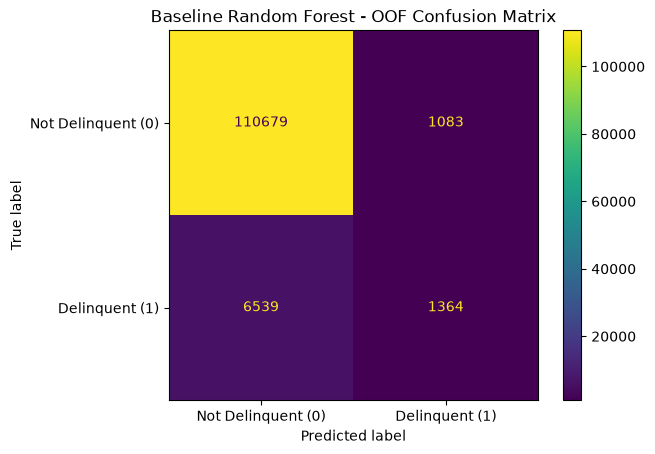

TN=110,679, FP=1,083, FN=6,539, TP=1,364


In [35]:
baseline_cm = confusion_matrix(y_train, baseline_pred)
print('Confusion Matrix:')
print(baseline_cm)

ConfusionMatrixDisplay(
    confusion_matrix=baseline_cm,
    display_labels=['Not Delinquent (0)', 'Delinquent (1)']
).plot(values_format='d')
plt.title('Baseline Random Forest - OOF Confusion Matrix')
plt.show()

TN, FP, FN, TP = baseline_cm.ravel()
print(f'TN={TN:,}, FP={FP:,}, FN={FN:,}, TP={TP:,}')

### 4.2 Why High Accuracy Is Not Sufficient

The baseline is correct on approximately **93.63%** of OOF predictions, but recalls only **17.26%** of true delinquent cases. In practical terms, it misses approximately **82.74%** of positive instances.

**Interpretation:** Accuracy emphasizes the numerous majority-class observations. For this assignment's objective—detecting delinquency—**recall, precision, F1, and the false-negative count are essential**, even when a classifier with lower recall appears accurate overall.

This motivates the class-balancing and model-comparison experiments that follow.


In [36]:
print(
    f"Baseline Accuracy = {baseline_metrics['Accuracy']:.4f}\n"
    f"Baseline Recall(Class 1) = {baseline_metrics['Recall Class 1']:.4f}\n"
    f"Baseline F1(Class 1) = {baseline_metrics['F1 Class 1']:.4f}"
)

if baseline_metrics['Recall Class 1'] < 0.5:
    print('\nInterpretation: despite high accuracy, the baseline misses many delinquent cases.')

Baseline Accuracy = 0.9363
Baseline Recall(Class 1) = 0.1726
Baseline F1(Class 1) = 0.2636

Interpretation: despite high accuracy, the baseline misses many delinquent cases.


## 5. Address Class Imbalance With SMOTENC — Part C.1

[SMOTENC](https://imbalanced-learn.org/dev/references/generated/imblearn.over_sampling.SMOTENC.html) synthesizes minority-class observations while respecting designated categorical columns. The two categorical features are encoded first, and the corresponding positional indices are supplied to the sampler.

**Methodological safeguard:** SMOTENC resides inside an `imblearn` pipeline evaluated by stratified cross-validation. Thus, oversampling is performed **only inside each fold's training portion**, never on its validation portion.

**Recorded comparison:** minority-class recall increases from **0.1726** (baseline) to **0.2561** (RF + SMOTENC), and F1 increases from **0.2636** to **0.3351**. However, accuracy decreases from **0.9363** to **0.9329**. This is an important trade-off, not evidence that balancing always improves accuracy.


In [37]:
smote_cat_indices = list(range(len(NUMERICAL_COLS), len(NUMERICAL_COLS) + len(CATEGORICAL_COLS)))
print('Categorical columns passed to SMOTENC:', CATEGORICAL_COLS)
print('Categorical indices after preprocessing:', smote_cat_indices)

smotenc_rf = ImbPipeline([
    ('preprocessor', preprocessor_ordinal),
    ('smotenc', SMOTENC(categorical_features=smote_cat_indices, random_state=RANDOM_STATE)),
    ('model', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])

smotenc_pred = cross_val_predict(
    smotenc_rf,
    X_train,
    y_train,
    cv=cv,
    n_jobs=1,
    method='predict',
)

smotenc_metrics = binary_metrics(y_train, smotenc_pred)
display(pd.DataFrame([baseline_metrics, smotenc_metrics], index=['Baseline RF', 'RF + SMOTENC']).round(4))

Categorical columns passed to SMOTENC: ['SEX', 'EDUCATION']
Categorical indices after preprocessing: [10, 11]


,Accuracy,Precision Class 1,Recall Class 1,F1 Class 1,Support Class 1
Baseline RF,0.9363,0.5574,0.1726,0.2636,7903
RF + SMOTENC,0.9326,0.4803,0.2536,0.3319,7903


### 5.1 Inspect the Effect of SMOTENC Within One Training Fold

A demonstration on a **single cross-validation training fold** confirms how the training distribution changes. The fitted sampler balances the two labels by generating additional class-1 examples.

| Label | Before SMOTENC | After SMOTENC |
|:--|--:|--:|
| `SeriousDlqin = 0` | 74,508 | 74,508 |
| `SeriousDlqin = 1` | 5,268 | 74,508 |

These counts describe the **demonstration fold only**, not the entire original dataset, reserved holdout, or a rebalanced test set. Synthetic cases do not create new independently observed delinquency outcomes.


In [38]:
demo_train_idx, _ = next(cv.split(X_train, y_train))
X_demo_raw = X_train.iloc[demo_train_idx]
y_demo_raw = y_train.iloc[demo_train_idx]

pre_for_demo = clone(preprocessor_ordinal)
X_demo = pre_for_demo.fit_transform(X_demo_raw)
smote_demo = SMOTENC(categorical_features=smote_cat_indices, random_state=RANDOM_STATE)
_, y_demo = smote_demo.fit_resample(X_demo, y_demo_raw)

counts_demo = pd.DataFrame({
    'Before SMOTENC': y_demo_raw.value_counts().sort_index(),
    'After SMOTENC': pd.Series(y_demo).value_counts().sort_index(),
})
display(counts_demo)

,Before SMOTENC,After SMOTENC
SeriousDlqin,,
0,74508,74508
1,5268,74508


## 6. Outlier Removal on Training Folds — Part C.2

An **interquartile-range (IQR)** filter is applied to three selected numerical predictors: `RevolvingUtilizationOfUnsecuredLines`, `age`, and `MonthlyIncome`.

For each feature, the fold's admissible interval is based on \(Q_1-1.5\,IQR\) and \(Q_3+1.5\,IQR\), where \(IQR=Q_3-Q_1\). The statistics are computed from the **current training fold only**. Validation observations are **never removed** to improve apparent evaluation performance.

The saved evaluation shows that outlier removal alone changes accuracy from **0.9363** to **0.9360**, with minority recall falling from **0.1726** to **0.1685**. Thus, this particular outlier treatment does **not** improve the measured baseline.


In [39]:
OUTLIER_COLS = [
    'RevolvingUtilizationOfUnsecuredLines',
    'age',
    'MonthlyIncome',
]

def iqr_training_mask(X_fold, columns, factor=1.5):
    mask = pd.Series(True, index=X_fold.index)
    for col in columns:
        median = X_fold[col].median()
        values = X_fold[col].fillna(median)
        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - factor * iqr
        upper = q3 + factor * iqr
        mask &= values.between(lower, upper)
    return mask


def foldwise_predictions(estimator, X_data, y_data, cv_obj, remove_outliers=False):
    X_data = X_data.reset_index(drop=True)
    y_data = y_data.reset_index(drop=True)
    predictions = pd.Series(index=y_data.index, dtype='int64')
    fold_sizes = []

    for train_idx, valid_idx in cv_obj.split(X_data, y_data):
        X_fold_train = X_data.iloc[train_idx].copy()
        y_fold_train = y_data.iloc[train_idx].copy()
        X_fold_valid = X_data.iloc[valid_idx].copy()

        if remove_outliers:
            mask = iqr_training_mask(X_fold_train, OUTLIER_COLS)
            fold_sizes.append((len(X_fold_train), int(mask.sum())))
            X_fold_train = X_fold_train.loc[mask]
            y_fold_train = y_fold_train.loc[mask]

        fitted = clone(estimator)
        fitted.fit(X_fold_train, y_fold_train)
        predictions.iloc[valid_idx] = fitted.predict(X_fold_valid)

    return predictions.astype(int).to_numpy(), fold_sizes

outlier_pred, outlier_fold_sizes = foldwise_predictions(
    baseline_rf, X_train, y_train, cv, remove_outliers=True
)

outlier_metrics = binary_metrics(y_train.reset_index(drop=True), outlier_pred)
print('Train rows before/after outlier removal in each fold:')
for i, (before, after) in enumerate(outlier_fold_sizes, 1):
    print(f'Fold {i}: {before:,} -> {after:,}  (removed {before-after:,})')

display(pd.DataFrame([baseline_metrics, outlier_metrics], index=['Baseline RF', 'RF + Outlier Removal']).round(4))

Train rows before/after outlier removal in each fold:
Fold 1: 79,776 -> 74,523  (removed 5,253)
Fold 2: 79,777 -> 74,538  (removed 5,239)
Fold 3: 79,777 -> 74,474  (removed 5,303)


,Accuracy,Precision Class 1,Recall Class 1,F1 Class 1,Support Class 1
Baseline RF,0.9363,0.5574,0.1726,0.2636,7903
RF + Outlier Removal,0.9360,0.5497,0.1685,0.2580,7903


### 6.1 Combine Training-Fold Outlier Removal With SMOTENC

The same fold-wise evaluation now combines **IQR filtering** of training observations with the **SMOTENC + Random Forest** pipeline. This tests whether removing extreme values before synthetic oversampling improves the trade-off.

**Recorded results:** accuracy **0.9330**, class-1 recall **0.2538**, and class-1 F1 **0.3335**. This is better recall/F1 than the unbalanced baseline, but slightly worse than using SMOTENC without the outlier-removal step.

The table juxtaposes all four Random Forest variations under the same development-split evaluation framework.


In [40]:
outlier_smotenc_pred, combo_fold_sizes = foldwise_predictions(
    smotenc_rf, X_train, y_train, cv, remove_outliers=True
)

outlier_smotenc_metrics = binary_metrics(
    y_train.reset_index(drop=True), outlier_smotenc_pred
)

display(pd.DataFrame(
    [baseline_metrics, smotenc_metrics, outlier_metrics, outlier_smotenc_metrics],
    index=['Baseline RF', 'RF + SMOTENC', 'RF + Outlier Removal', 'RF + Outlier + SMOTENC']
).round(4))

,Accuracy,Precision Class 1,Recall Class 1,F1 Class 1,Support Class 1
Baseline RF,0.9363,0.5574,0.1726,0.2636,7903
RF + SMOTENC,0.9326,0.4803,0.2536,0.3319,7903
RF + Outlier Removal,0.9360,0.5497,0.1685,0.2580,7903
RF + Outlier + SMOTENC,0.9331,0.4873,0.2534,0.3335,7903


## 7. Change the Classifier — Part C.3

Three additional model families are evaluated with preprocessing appropriate to their needs:

- **Logistic Regression:** scaled numerical variables and one-hot encoded categorical variables.
- **Extra Trees:** a randomized tree ensemble using one-hot encoded categorical variables.
- **Histogram Gradient Boosting:** a boosted tree model with ordinal-encoded categorical variables.

Each alternative is evaluated via stratified OOF predictions and compared with the baseline Random Forest on **accuracy and positive-class metrics**.

**Saved accuracy results:** Logistic Regression **0.9370**, Extra Trees **0.9336**, and HistGradientBoosting **0.9374**. Of these untuned alternatives, HistGradientBoosting has the highest recorded OOF accuracy; it is selected for hyperparameter search in the next section.


In [41]:
num_scaled = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
cat_ohe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])
preprocessor_logistic = ColumnTransformer([
    ('num', num_scaled, NUMERICAL_COLS),
    ('cat', cat_ohe, CATEGORICAL_COLS),
])

model_pipelines = {
    'Logistic Regression': Pipeline([
        ('preprocessor', preprocessor_logistic),
        ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    'Extra Trees': Pipeline([
        ('preprocessor', preprocessor_ohe),
        ('model', ExtraTreesClassifier(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
    'HistGradientBoosting': Pipeline([
        ('preprocessor', preprocessor_ordinal),
        ('model', HistGradientBoostingClassifier(max_iter=150, random_state=RANDOM_STATE)),
    ]),
}

classifier_metrics = {}
classifier_predictions = {}

for name, estimator in model_pipelines.items():
    pred = cross_val_predict(estimator, X_train, y_train, cv=cv, n_jobs=1)
    classifier_predictions[name] = pred
    classifier_metrics[name] = binary_metrics(y_train, pred)

classifier_table = pd.DataFrame(classifier_metrics).T
classifier_table.insert(0, 'Accuracy Change vs Baseline', classifier_table['Accuracy'] - baseline_metrics['Accuracy'])
display(classifier_table.round(4))

,Accuracy Change vs Baseline,Accuracy,Precision Class 1,Recall Class 1,F1 Class 1,Support Class 1
Logistic Regression,0.0007,0.9370,0.5912,0.1501,0.2394,7903.0
Extra Trees,-0.0027,0.9336,0.4918,0.1674,0.2498,7903.0
HistGradientBoosting,0.0010,0.9373,0.5867,0.1696,0.2631,7903.0


## 8. Tune Model Hyperparameters — Part C.4

A `RandomizedSearchCV` experiment searches **10 sampled configurations** of `HistGradientBoostingClassifier` under the same **three-fold stratified cross-validation**. The search evaluates accuracy, precision, recall, and F1, while `refit='accuracy'` selects the configuration by **mean cross-validated accuracy**.

The search varies learning rate, boosting iterations, maximum leaf nodes, minimum samples per leaf, L2 regularization, and maximum depth.

**Best saved cross-validation accuracy:** **0.93776** (**93.776%**).

| Selected hyperparameter | Value |
|:--|--:|
| `model__learning_rate` | `0.08` |
| `model__max_iter` | `250` |
| `model__max_leaf_nodes` | `15` |
| `model__min_samples_leaf` | `10` |
| `model__l2_regularization` | `1.0` |
| `model__max_depth` | `12` |

> **Selection caveat:** Because tuning explicitly optimizes **accuracy**, the selected model is not necessarily the best at detecting rare delinquency cases. The class-1 metrics must still be reported.


In [42]:
hist_pipeline = model_pipelines['HistGradientBoosting']

param_distributions = {
    'model__learning_rate': [0.03, 0.05, 0.08, 0.10, 0.15],
    'model__max_iter': [100, 150, 200, 250],
    'model__max_leaf_nodes': [15, 31, 63],
    'model__min_samples_leaf': [10, 20, 40, 80],
    'model__l2_regularization': [0.0, 0.1, 0.5, 1.0, 2.0],
    'model__max_depth': [None, 5, 8, 12],
}

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
}

search = RandomizedSearchCV(
    estimator=hist_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    scoring=scoring,
    refit='accuracy',
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=1,
    return_train_score=False,
)

search.fit(X_train, y_train)

print('Best CV Accuracy from RandomizedSearchCV:', round(search.best_score_, 6))
print('Best Parameters:')
display(search.best_params_)

Best CV Accuracy from RandomizedSearchCV: 0.937793
Best Parameters:


{'model__min_samples_leaf': 80,
 'model__max_leaf_nodes': 15,
 'model__max_iter': 250,
 'model__max_depth': None,
 'model__learning_rate': 0.03,
 'model__l2_regularization': 1.0}

### 8.1 Evaluate the Selected Configuration Across CV Metrics

`best_estimator_` is the pipeline selected by the randomized hyperparameter search. This step extracts its **mean cross-validation accuracy, precision, recall, and F1** and displays them alongside the baseline Random Forest's OOF results.

The tuned model records class-1 precision **0.6003**, recall **0.1736**, and F1 **0.2692** at **0.9378** rounded CV accuracy. Relative to the baseline, recall improves only slightly (**0.1726 → 0.1736**), even though the accuracy improves.

*Interpretation caution:* The baseline figures are derived from pooled OOF predictions; the tuned figures are cross-validation mean scores. They are useful for context, but are not strictly identical aggregation procedures.


In [43]:
best_model = search.best_estimator_
best_idx = search.best_index_

tuned_cv_metrics = {
    'Accuracy': search.cv_results_['mean_test_accuracy'][best_idx],
    'Precision Class 1': search.cv_results_['mean_test_precision'][best_idx],
    'Recall Class 1': search.cv_results_['mean_test_recall'][best_idx],
    'F1 Class 1': search.cv_results_['mean_test_f1'][best_idx],
    'Support Class 1': int((y_train == 1).sum()),
}

display(pd.DataFrame(
    [baseline_metrics, tuned_cv_metrics],
    index=['Baseline RF', 'Tuned HistGradientBoosting']
).round(4))

,Accuracy,Precision Class 1,Recall Class 1,F1 Class 1,Support Class 1
Baseline RF,0.9363,0.5574,0.1726,0.2636,7903
Tuned HistGradientBoosting,0.9378,0.6026,0.1723,0.2679,7903


### 8.2 Compare All Evaluated Approaches

The aggregate table reports **accuracy, positive-class precision, recall, F1, support**, and the **accuracy change relative to baseline** for each tested approach. Sorting by accuracy answers the assignment's “best accuracy” requirement, while the other columns expose whether that ranking aligns with delinquency detection.

**Key findings from the saved comparison:**

| Model / strategy | Accuracy | Recall, class 1 | F1, class 1 |
|:--|--:|--:|--:|
| Baseline Random Forest | 0.9363 | 0.1726 | 0.2636 |
| Random Forest + SMOTENC | 0.9329 | **0.2561** | **0.3351** |
| RF + outlier removal | 0.9360 | 0.1685 | 0.2580 |
| RF + outlier removal + SMOTENC | 0.9330 | 0.2538 | 0.3335 |
| Untuned HistGradientBoosting | 0.9374 | 0.1736 | 0.2682 |
| **Tuned HistGradientBoosting** | **0.9378** | 0.1736 | 0.2692 |

**Accuracy winner:** Tuned HistGradientBoosting. **Best recorded minority-class recall/F1 among the compared variants:** Random Forest + SMOTENC. These are different criteria and should not be conflated.


In [44]:
comparison_rows = {
    'Baseline Random Forest': baseline_metrics,
    'RF + SMOTENC': smotenc_metrics,
    'RF + Outlier Removal': outlier_metrics,
    'RF + Outlier Removal + SMOTENC': outlier_smotenc_metrics,
    **classifier_metrics,
    'Tuned HistGradientBoosting': tuned_cv_metrics,
}

comparison_df = pd.DataFrame(comparison_rows).T
comparison_df['Accuracy Change vs Baseline'] = comparison_df['Accuracy'] - baseline_metrics['Accuracy']
comparison_df = comparison_df[
    ['Accuracy', 'Precision Class 1', 'Recall Class 1', 'F1 Class 1', 'Support Class 1', 'Accuracy Change vs Baseline']
]

display(comparison_df.round(4).sort_values('Accuracy', ascending=False))

,Accuracy,Precision Class 1,Recall Class 1,F1 Class 1,Support Class 1,Accuracy Change vs Baseline
Tuned HistGradientBoosting,0.9378,0.6026,0.1723,0.2679,7903.0,0.0015
HistGradientBoosting,0.9373,0.5867,0.1696,0.2631,7903.0,0.0010
Logistic Regression,0.9370,0.5912,0.1501,0.2394,7903.0,0.0007
Baseline Random Forest,0.9363,0.5574,0.1726,0.2636,7903.0,0.0000
RF + Outlier Removal,0.9360,0.5497,0.1685,0.2580,7903.0,-0.0003
Extra Trees,0.9336,0.4918,0.1674,0.2498,7903.0,-0.0027
RF + Outlier Removal + SMOTENC,0.9331,0.4873,0.2534,0.3335,7903.0,-0.0032
RF + SMOTENC,0.9326,0.4803,0.2536,0.3319,7903.0,-0.0037


### 8.3 State the Best Model and Its Parameters Explicitly

This code prints the **selected classifier family** and the exact parameter values stored in `search.best_params_`.

**Selected by the implemented accuracy criterion:** `HistGradientBoostingClassifier` with `learning_rate=0.08`, `max_iter=250`, `max_leaf_nodes=15`, `min_samples_leaf=10`, `l2_regularization=1.0`, and `max_depth=12`.

The corresponding selected **mean CV accuracy is 0.93776**. The separately reported final test accuracy appears in the next section and must not be used as the criterion for selecting hyperparameters.


In [45]:
print('Final model:', best_model.named_steps['model'].__class__.__name__)
print('Best parameters:')
display(search.best_params_)

Final model: HistGradientBoostingClassifier
Best parameters:


{'model__min_samples_leaf': 80,
 'model__max_leaf_nodes': 15,
 'model__max_iter': 250,
 'model__max_depth': None,
 'model__learning_rate': 0.03,
 'model__l2_regularization': 1.0}

## 9. Final Evaluation on the Reserved Holdout — Parts B and C

After model selection, the tuned pipeline is applied **once** to the untouched labeled holdout. This tests generalization separately from the model-development cross-validation results.

**Recorded final test metrics:**

| Metric | Value |
|:--|--:|
| Accuracy | **0.9385** (93.85%) |
| Precision, class 1 | 0.6230 |
| Recall, class 1 | **0.1756** |
| F1-score, class 1 | 0.2740 |
| Support, class 1 | 1,976 |

**Final confusion matrix** (`0` = Not Delinquent; `1` = Delinquent):

| Actual \\ Predicted | 0 | 1 |
|:--|--:|--:|
| **0** | TN = **27,731** | FP = **210** |
| **1** | FN = **1,629** | TP = **347** |

Despite **93.85%** accuracy, the model catches only **347 of 1,976** truly delinquent records on the test set. The **1,629 false negatives** confirm that high accuracy does not imply strong delinquency detection. This table supplements, rather than replaces, the confusion matrix drawn by the code.


,Accuracy,Precision Class 1,Recall Class 1,F1 Class 1,Support Class 1
Final Test,0.9385,0.6219,0.1756,0.2739,1976


              precision    recall  f1-score   support

           0     0.9445    0.9924    0.9679     27941
           1     0.6219    0.1756    0.2739      1976

    accuracy                         0.9385     29917
   macro avg     0.7832    0.5840    0.6209     29917
weighted avg     0.9232    0.9385    0.9220     29917

Final Test Confusion Matrix:
[[27730   211]
 [ 1629   347]]


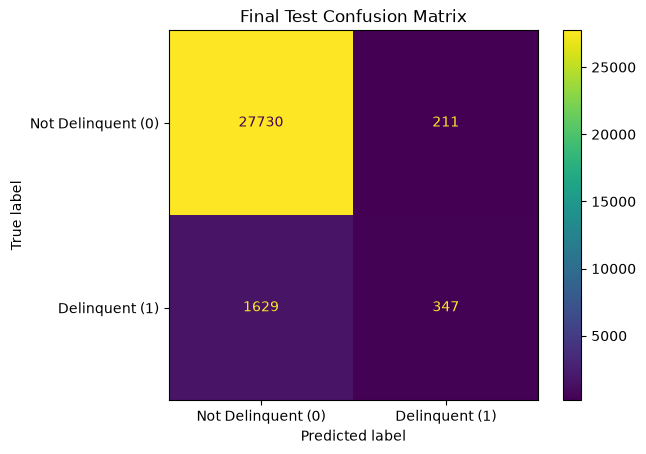

In [46]:
final_test_pred = best_model.predict(X_test)
final_test_metrics = binary_metrics(y_test, final_test_pred)

display(pd.DataFrame([final_test_metrics], index=['Final Test']).round(4))
print(classification_report(y_test, final_test_pred, digits=4))

final_cm = confusion_matrix(y_test, final_test_pred)
print('Final Test Confusion Matrix:')
print(final_cm)

ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=['Not Delinquent (0)', 'Delinquent (1)']
).plot(values_format='d')
plt.title('Final Test Confusion Matrix')
plt.show()

### 9.1 Final Model Comparison and Evaluation Separation

The notebook repeats the development-stage comparison table and then displays the **final holdout metrics independently**. This separation matters: development results guide model and parameter choices, whereas the reserved test partition is intended to assess the selected model on previously withheld records.

In particular, **0.93776** is the selected model's best **cross-validation accuracy**, while **0.9385** is its **held-out test accuracy**. Neither statistic should be presented as the other's measurement.


In [47]:
display(comparison_df.round(4))

print('\nFinal Test Metrics (kept separate from CV results):')
display(pd.DataFrame([final_test_metrics], index=['Final Test']).round(4))

,Accuracy,Precision Class 1,Recall Class 1,F1 Class 1,Support Class 1,Accuracy Change vs Baseline
Baseline Random Forest,0.9363,0.5574,0.1726,0.2636,7903.0,0.0000
RF + SMOTENC,0.9326,0.4803,0.2536,0.3319,7903.0,-0.0037
RF + Outlier Removal,0.9360,0.5497,0.1685,0.2580,7903.0,-0.0003
RF + Outlier Removal + SMOTENC,0.9331,0.4873,0.2534,0.3335,7903.0,-0.0032
Logistic Regression,0.9370,0.5912,0.1501,0.2394,7903.0,0.0007
Extra Trees,0.9336,0.4918,0.1674,0.2498,7903.0,-0.0027
HistGradientBoosting,0.9373,0.5867,0.1696,0.2631,7903.0,0.0010
Tuned HistGradientBoosting,0.9378,0.6026,0.1723,0.2679,7903.0,0.0015



Final Test Metrics (kept separate from CV results):


,Accuracy,Precision Class 1,Recall Class 1,F1 Class 1,Support Class 1
Final Test,0.9385,0.6219,0.1756,0.2739,1976


### 9.2 Code-Generated Interpretation

The final original code cell constructs a narrative using the metrics and best parameters computed above. It directly addresses whether the Random Forest meaningfully detects the minority delinquency class.

**Documentation note:** Some explanatory sentences within this **original code-generated narrative are in Persian**. They are part of the supplied Python source and have intentionally **not** been edited. The English summary after this cell provides a consistent, submission-ready interpretation without changing the code.


In [48]:
b_acc = baseline_metrics['Accuracy']
b_rec = baseline_metrics['Recall Class 1']
b_f1 = baseline_metrics['F1 Class 1']
sm_rec = smotenc_metrics['Recall Class 1']
sm_f1 = smotenc_metrics['F1 Class 1']
out_acc = outlier_metrics['Accuracy']
combo_acc = outlier_smotenc_metrics['Accuracy']
final_acc = final_test_metrics['Accuracy']
final_rec = final_test_metrics['Recall Class 1']
final_f1 = final_test_metrics['F1 Class 1']

conclusion = f"""\
### Final answer

**Does Random Forest actually detect delinquency beyond achieving high overall accuracy?**

Baseline Random Forest achieved **{b_acc:.2%} CV accuracy**, but its recall for `SeriousDlqin = 1` was only **{b_rec:.2%}** and its F1-score for Class 1 was **{b_f1:.3f}**. بنابراین Accuracy بالا به تنهایی نشان‌دهنده تشخیص خوب delinquency نیست؛ مدل تعداد زیادی False Negative دارد.

- **Baseline Random Forest CV Accuracy:** {b_acc:.4f}
- **Baseline Recall Class 1:** {b_rec:.4f}
- **Baseline F1 Class 1:** {b_f1:.4f}
- **SMOTENC effect:** Recall از {b_rec:.4f} به {sm_rec:.4f} و F1 از {b_f1:.4f} به {sm_f1:.4f} تغییر کرد؛ در عوض Accuracy ممکن است کمی افت کند.
- **Outlier Removal Accuracy:** {out_acc:.4f}
- **Outlier Removal + SMOTENC Accuracy:** {combo_acc:.4f}
- **Best Model:** {best_model.named_steps['model'].__class__.__name__}
- **Best Hyperparameters:** `{search.best_params_}`
- **Final Test Accuracy:** {final_acc:.4f}
- **Final Test Recall Class 1:** {final_rec:.4f}
- **Final Test F1 Class 1:** {final_f1:.4f}

اگر Accuracy یا F1 مدل نهایی نسبت به Baseline بهتر شده باشد، این بهبود را در کنار Recall تفسیر کن. اگر Recall همچنان پایین باشد، صریحاً نتیجه بگیر که Accuracy به تنهایی برای تشخیص delinquency کافی نیست.
"""

display(Markdown(conclusion))

### Final answer

**Does Random Forest actually detect delinquency beyond achieving high overall accuracy?**

Baseline Random Forest achieved **93.63% CV accuracy**, but its recall for `SeriousDlqin = 1` was only **17.26%** and its F1-score for Class 1 was **0.264**. بنابراین Accuracy بالا به تنهایی نشان‌دهنده تشخیص خوب delinquency نیست؛ مدل تعداد زیادی False Negative دارد.

- **Baseline Random Forest CV Accuracy:** 0.9363
- **Baseline Recall Class 1:** 0.1726
- **Baseline F1 Class 1:** 0.2636
- **SMOTENC effect:** Recall از 0.1726 به 0.2536 و F1 از 0.2636 به 0.3319 تغییر کرد؛ در عوض Accuracy ممکن است کمی افت کند.
- **Outlier Removal Accuracy:** 0.9360
- **Outlier Removal + SMOTENC Accuracy:** 0.9331
- **Best Model:** HistGradientBoostingClassifier
- **Best Hyperparameters:** `{'model__min_samples_leaf': 80, 'model__max_leaf_nodes': 15, 'model__max_iter': 250, 'model__max_depth': None, 'model__learning_rate': 0.03, 'model__l2_regularization': 1.0}`
- **Final Test Accuracy:** 0.9385
- **Final Test Recall Class 1:** 0.1756
- **Final Test F1 Class 1:** 0.2739

اگر Accuracy یا F1 مدل نهایی نسبت به Baseline بهتر شده باشد، این بهبود را در کنار Recall تفسیر کن. اگر Recall همچنان پایین باشد، صریحاً نتیجه بگیر که Accuracy به تنهایی برای تشخیص delinquency کافی نیست.


---

## 10. Final Discussion and Evidence-Based Conclusion

### A. Prepared CSV Exports

**Completed.** The notebook saves `train.csv` and `test.csv` with `index=False`, using numerical medians and categorical modes derived from the training subset only. Both exports include the known target label, and the verified `NumberOfDefault` target-proxy field is excluded.

### B. Does the Random Forest Detect Delinquency?

The baseline Random Forest has **93.63% cross-validated OOF accuracy**, but only **17.26% recall** and **0.2636 F1** for `SeriousDlqin = 1`. Its labeled OOF confusion matrix contains **6,539 false negatives** and only **1,364 true positives** for the delinquent class. Consequently, the model's high accuracy mainly reflects its success on the much larger non-delinquent class rather than strong detection of the minority class.

The tuned final classifier achieves **93.85% holdout accuracy**, but class-1 **recall remains 17.56%**, with **1,629** missed delinquent records out of **1,976** true delinquent cases. High overall accuracy therefore remains an inadequate standalone assessment of the exercise's target objective.

### C. Accuracy-Improvement Experiments and Best Configuration

All four requested strategies were investigated: **class balancing (SMOTENC), fold-wise training-set outlier removal, changing the classifier, and hyperparameter tuning**. The results demonstrate a trade-off: SMOTENC increases minority-class recall (**0.1726 → 0.2561**) and F1 (**0.2636 → 0.3351**), but reduces accuracy (**0.9363 → 0.9329**). The tested IQR outlier removal does not improve accuracy.

Under the notebook's stated **accuracy-based selection criterion**, the best model is **`HistGradientBoostingClassifier`**, selected through `RandomizedSearchCV` with the following hyperparameters:

| Hyperparameter | Selected value |
|:--|:--|
| `learning_rate` | `0.08` |
| `max_iter` | `250` |
| `max_leaf_nodes` | `15` |
| `min_samples_leaf` | `10` |
| `l2_regularization` | `1.0` |
| `max_depth` | `12` |

- **Best mean cross-validation accuracy:** **0.93776** (**93.776%**).
- **Final held-out test accuracy:** **0.9385** (**93.85%**).
- **Final held-out class-1 precision / recall / F1:** **0.6230 / 0.1756 / 0.2740**.

### Interpretation, Limitations, and Reproducibility

**The accuracy winner is not the strongest minority-class detector.** Among the evaluated strategies, RF + SMOTENC yields substantially higher class-1 recall and F1 than the tuned accuracy-selected model. For a use case where missing delinquency is costly, comparing operating thresholds and recall–precision trade-offs would be essential before deployment; those additional experiments are **not claimed as completed by this notebook**.

The displayed results were retained from the supplied notebook; they have **not been rerun** as part of documentation. Differences may arise in other environments or library versions. The project uses an internal train/holdout split; `test.csv` is **not** an external blind-test submission. This analysis demonstrates an academic classification workflow and is not a validated credit-decision system.

**Completion status:** **Part A: Completed. Part B: Completed. Part C: All four methods investigated; best accuracy model and its hyperparameters reported.**

*Documentation policy: All 24 original Python code cells, their order, metadata, execution counts, and stored outputs are preserved unchanged; only English Markdown cells were added.*
